In [1]:
import glob

import numpy as np
import pandas as pd
from skimage import io
import matplotlib.pyplot as plt

from corebreakout import defaults
from corebreakout import CoreSegmenter
from corebreakout.datasets import PolygonDataset

Using TensorFlow backend.


In [2]:
model_dir = defaults.TRAIN_DIR / 'cb_default20190930T1556'

weights_path = model_dir / 'mask_rcnn_cb_default_0093.h5'

In [3]:
segmenter = CoreSegmenter(model_dir, weights_path)

W1004 13:18:13.642319 139684232910656 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/keras/backend/tensorflow_backend.py:517: The name tf.placeholder is deprecated. Please use tf.compat.v1.placeholder instead.

W1004 13:18:13.656738 139684232910656 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/keras/backend/tensorflow_backend.py:74: The name tf.get_default_graph is deprecated. Please use tf.compat.v1.get_default_graph instead.

W1004 13:18:13.659446 139684232910656 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/keras/backend/tensorflow_backend.py:4138: The name tf.random_uniform is deprecated. Please use tf.random.uniform instead.

W1004 13:18:13.674696 139684232910656 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/keras/backend/tensorflow_backend.py:1919: The name tf.nn.fused_batch_norm is d

Building MRCNN model from directory: /home/ross/Dropbox/models/corebreakout/pretrain/cb_default20190930T1556


W1004 13:18:15.441904 139684232910656 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/keras/backend/tensorflow_backend.py:2018: The name tf.image.resize_nearest_neighbor is deprecated. Please use tf.compat.v1.image.resize_nearest_neighbor instead.

W1004 13:18:15.727021 139684232910656 deprecation_wrapper.py:119] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/mask_rcnn-2.1-py3.7.egg/mrcnn/model.py:341: The name tf.log is deprecated. Please use tf.math.log instead.

W1004 13:18:15.733533 139684232910656 deprecation.py:323] From /home/ross/anaconda3/envs/core-dev/lib/python3.7/site-packages/mask_rcnn-2.1-py3.7.egg/mrcnn/model.py:399: add_dispatch_support.<locals>.wrapper (from tensorflow.python.ops.array_ops) is deprecated and will be removed in a future version.
Instructions for updating:
Use tf.where in 2.0, which has the same broadcast rule as np.where
W1004 13:18:15.737889 139684232910656 deprecation.py:506] From /h

Loading model weights from file: /home/ross/Dropbox/models/corebreakout/pretrain/cb_default20190930T1556/mask_rcnn_cb_default_0093.h5
Re-starting from epoch 93


In [4]:
#test_dataset = PolygonDataset()
#test_dataset.collect_annotated_images(defaults.DATASET_DIR, 'test')
#test_dataset.prepare()

#print(test_dataset)

In [5]:
#test_img = test_dataset.load_image(2)

#fig, ax = plt.subplots(figsize=(25,25))
#ax.imshow(test_img)

In [6]:
#column = segmenter.segment(test_img, [2102.,2104.], show=True)

In [7]:
#fig, ax = column.plot(figsize=(15, 60), minor_precision=0.02, minor_tick_size=10)

Reading file: /home/ross/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-3A/converted/S00102619.jpeg


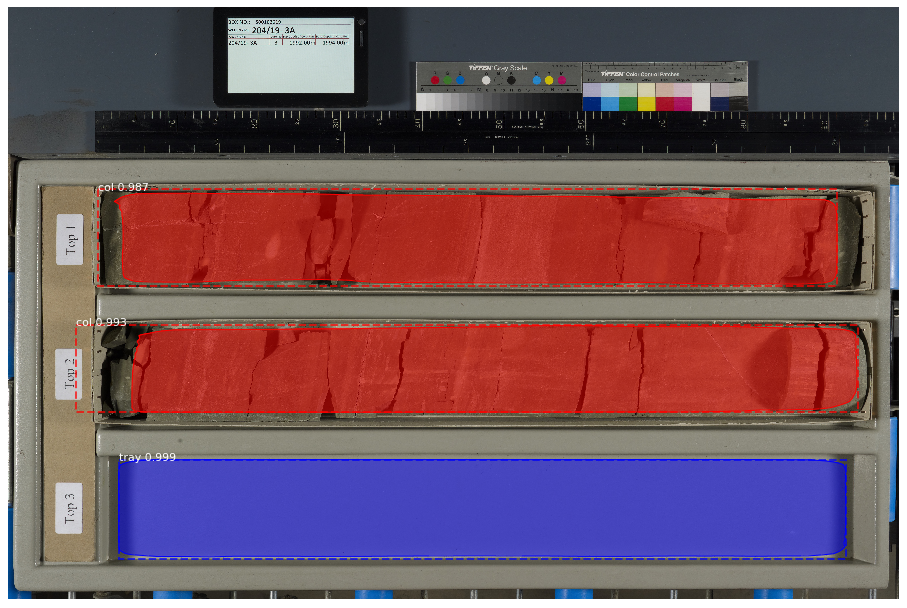

endpoint coords: (883, 6707)
(1992.0, 1993.0) (1993.0, 1994.0) 0.0
Reading file: /home/ross/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-3A/converted/S00102620.jpeg


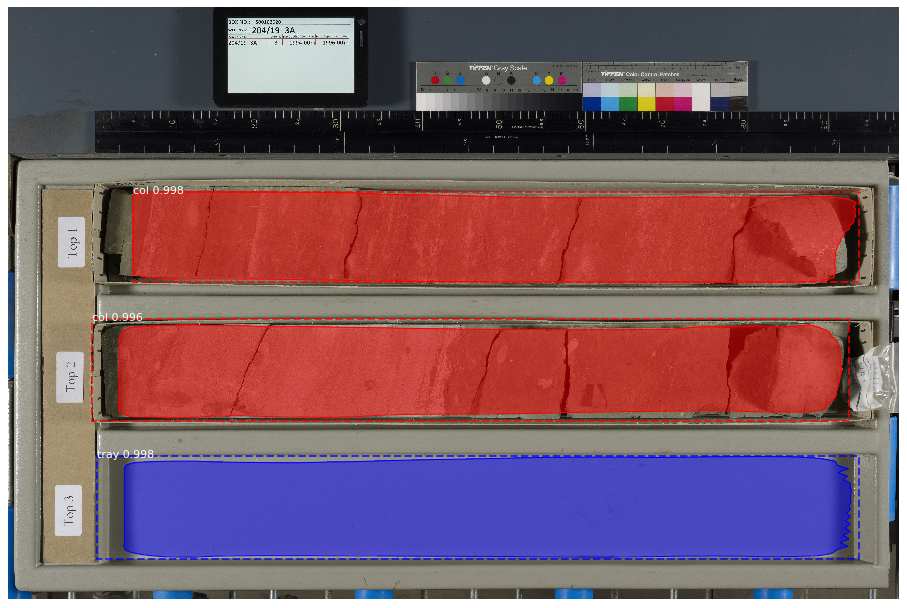

endpoint coords: (923, 6751)
(1994.0, 1995.0) (1995.0, 1996.0) 0.0


In [8]:
inference_dir = '/home/ross/Dropbox/core_data/well_core_data/wos_data/schiehallion-complex/204-19-3A/converted/'

#show_colors = [(1., 0., 0.), (0.,0.,1.)]

fnames = ['S00102619.jpeg', 'S00102620.jpeg']

depth_ranges = [[1992.,1994.], [1994., 1996.]]

cols = []

for img_f, depth_r in zip(fnames, depth_ranges):
    
    col = segmenter.segment(inference_dir + img_f, depth_r, show=True) #, colors=show_colors)
    cols.append(col)

In [9]:
column = cols[0] + cols[1]

(1992.0, 1994.0) (1994.0, 1996.0) 0.0


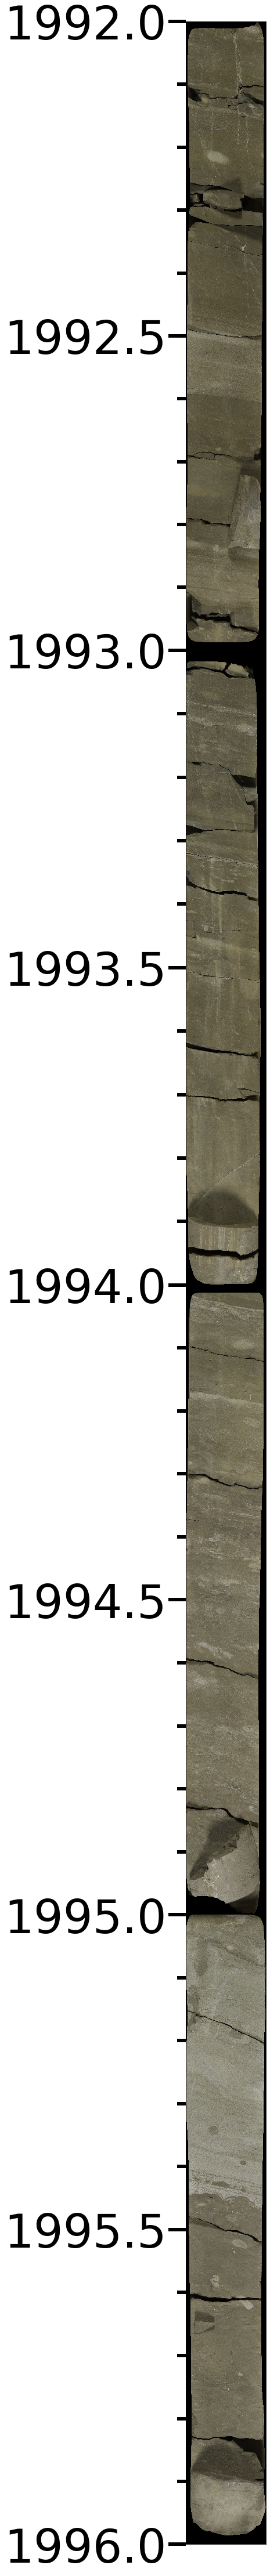

In [32]:
fig, ax = column.plot(figsize=(25, 80), major_precision=0.5, minor_precision=0.1,
                      minor_format_str='{:.1f}', major_tick_size=80, minor_tick_size=5)

#ax.set_ytickt([], minor=True)

ax.tick_params(which='major', length=30, width=6)
ax.tick_params(which='minor', length=15, width=6, color='black', labelleft=False)

In [33]:
fig.savefig('/home/ross/Pictures/resulting_column5.png')

In [36]:
d = {'a' : 1}
d.update({})
d

{'a': 1}